# 04 - Model Development

Used car price prediction, step 4 of the project. Each step has its own notebook:

- 01 - data loading, exploration, cleaning, and preprocessing
- 02 - exploratory data analysis
- 03 - feature selection
- **04 - model development (this notebook)**

**Goal:** train three regression models, compare them, and see which setup predicts used car prices best.

**What we compare:**

- Three models: Linear Regression (a simple baseline), Random Forest, and Gradient Boosting. All use default settings. Tuning comes in the next notebook.
- Two ways of predicting the price: the **raw price**, or the **log of the price** (predictions are converted back to rupees, so every score below is in rupees and can be compared directly).

That makes 6 combinations.

**How the winner is chosen:** by 5-fold cross-validation on the **training data**. The test set is not used to choose. Test scores are still reported, because they show how the models do on cars they have never seen.

Note: this notebook takes roughly 10 to 15 minutes to run.

## 1. Setup

In [1]:
# Import the libraries used in this notebook
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")       # keep the output readable
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)   # folder for the charts

# Print the library versions (we pin them in requirements.txt later)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1


In [2]:
# A small helper: tidy the layout, save the chart as a PNG file, then show it
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the data and the selected features

In [3]:
# Load the cleaned data (notebook 01) and the selected features (notebook 03).
# First try to read both straight from the GitHub repo. If the repo is private, or the files
# have not been pushed yet, fall back to uploading them by hand (a file picker appears twice).
import urllib.request

BASE_URL = "https://raw.githubusercontent.com/MirajAdhikari/used-car-price-prediction/main/data/processed/"

try:
    clean = pd.read_csv(BASE_URL + "cardekho_cleaned.csv")
    selection = json.load(urllib.request.urlopen(BASE_URL + "selected_features.json"))
    print("Loaded both files from GitHub.")
except Exception:
    from google.colab import files
    # The upload window can only pick files from one folder at a time,
    # so we ask for the two files separately. Each file is saved in the current folder.
    print("Step 1 of 2: choose cardekho_cleaned.csv")
    files.upload()
    print("Step 2 of 2: choose selected_features.json")
    files.upload()
    clean = pd.read_csv("cardekho_cleaned.csv")
    with open("selected_features.json") as file:
        selection = json.load(file)
    print("Loaded both files from the upload.")

print("Shape (rows, columns):", clean.shape)


Step 1 of 2: choose cardekho_cleaned.csv


Saving cardekho_cleaned.csv to cardekho_cleaned.csv
Step 2 of 2: choose selected_features.json


Saving selected_features.json to selected_features.json
Loaded both files from the upload.
Shape (rows, columns): (15240, 13)


In [4]:
# The features chosen in notebook 03
numeric_features = selection["numeric_features"]
categorical_features = selection["categorical_features"]
print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)
print("Dropped in notebook 03:", selection["dropped_features"])

# The same 80/20 split as in the earlier notebooks (random_state=42)
X = clean[numeric_features + categorical_features]
y = clean["selling_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTraining rows:", len(X_train), "| Test rows:", len(X_test))

Numeric features:     ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Categorical features: ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
Dropped in notebook 03: ['km_per_year']

Training rows: 12192 | Test rows: 3048


## 3. Metrics

All errors are shown in **lakh rupees** (1 lakh = 100,000 rupees). We report four numbers:

- **RMSE:** the typical size of the error, with large errors counting extra. It is dominated by expensive cars.
- **MAE:** the average size of the error.
- **R2:** the share of the price variation the model explains (1.0 is perfect).
- **Median % error:** for a typical car, by what percentage is the prediction off? This is the easiest number to understand, and it treats cheap and expensive cars equally.

In [5]:
# Median percentage error: the middle value of |actual - predicted| / actual, as a percent
def median_pct_error(y_true, y_pred):
    return np.median(np.abs(y_true - y_pred) / y_true) * 100

# Compute all four metrics for a set of predictions (errors in lakh rupees)
def evaluate(y_true, y_pred):
    return {
        "RMSE (lakh)": np.sqrt(mean_squared_error(y_true, y_pred)) / 100_000,
        "MAE (lakh)": mean_absolute_error(y_true, y_pred) / 100_000,
        "R2": r2_score(y_true, y_pred),
        "Median % error": median_pct_error(y_true, y_pred),
    }

## 4. The models

Every model sits inside a scikit-learn `Pipeline` together with the preprocessing from notebook 01 (standardize the numeric columns and one-hot encode the text columns). Because the preprocessing is inside the pipeline, it is fitted only on the training part of each split, so nothing leaks from the validation or test data.

For the log-price versions, the pipeline is wrapped in `TransformedTargetRegressor`. It takes the log of the price for training and converts predictions back to rupees automatically.

In [6]:
# The preprocessing step (the same idea as in notebook 01).
# sparse_output=False gives a normal table, which all three models accept.
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])

# The three models, all with default settings (tuning comes in the next notebook)
base_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
target_names = ["raw price", "log price"]

# Build one complete model: preprocessing + model, trained on raw or log price
def build_model(model_name, target_name):
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", clone(base_models[model_name])),
    ])
    if target_name == "log price":
        return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)
    return pipeline

## 5. Cross-validation on the training data

5-fold cross-validation splits the training data into 5 parts. Each part takes a turn as the validation set while the model trains on the other 4. The average over the 5 turns is a more reliable score than a single split. The scores here are what we use to choose the winner.

In [7]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# The scores to collect in every fold (all computed on prices in rupees)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
    "median_pct": make_scorer(median_pct_error, greater_is_better=False),
}

start = time.time()
cv_rows = []
for target_name in target_names:
    for model_name in base_models:
        scores = cross_validate(build_model(model_name, target_name), X_train, y_train,
                                cv=kfold, scoring=scoring)
        cv_rows.append({
            "Model": model_name,
            "Target": target_name,
            "CV RMSE (lakh)": -scores["test_rmse"].mean() / 100_000,
            "CV MAE (lakh)": -scores["test_mae"].mean() / 100_000,
            "CV R2": scores["test_r2"].mean(),
            "CV median % error": -scores["test_median_pct"].mean(),
        })
        print(f"Done: {model_name} ({target_name}) after {round(time.time() - start)} seconds")

cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE (lakh)").reset_index(drop=True)
cv_table.round(3)

Done: Linear Regression (raw price) after 1 seconds
Done: Random Forest (raw price) after 40 seconds
Done: Gradient Boosting (raw price) after 51 seconds
Done: Linear Regression (log price) after 55 seconds
Done: Random Forest (log price) after 92 seconds
Done: Gradient Boosting (log price) after 105 seconds


,Model,Target,CV RMSE (lakh),CV MAE (lakh),CV R2,CV median % error
0,Gradient Boosting,raw price,2.299,1.009,0.921,10.204
1,Random Forest,raw price,2.315,1.010,0.921,9.968
2,Gradient Boosting,log price,2.336,0.994,0.919,9.878
3,Random Forest,log price,2.397,1.010,0.914,9.969
4,Linear Regression,log price,2.826,1.138,0.882,10.939
5,Linear Regression,raw price,3.912,1.779,0.774,16.128


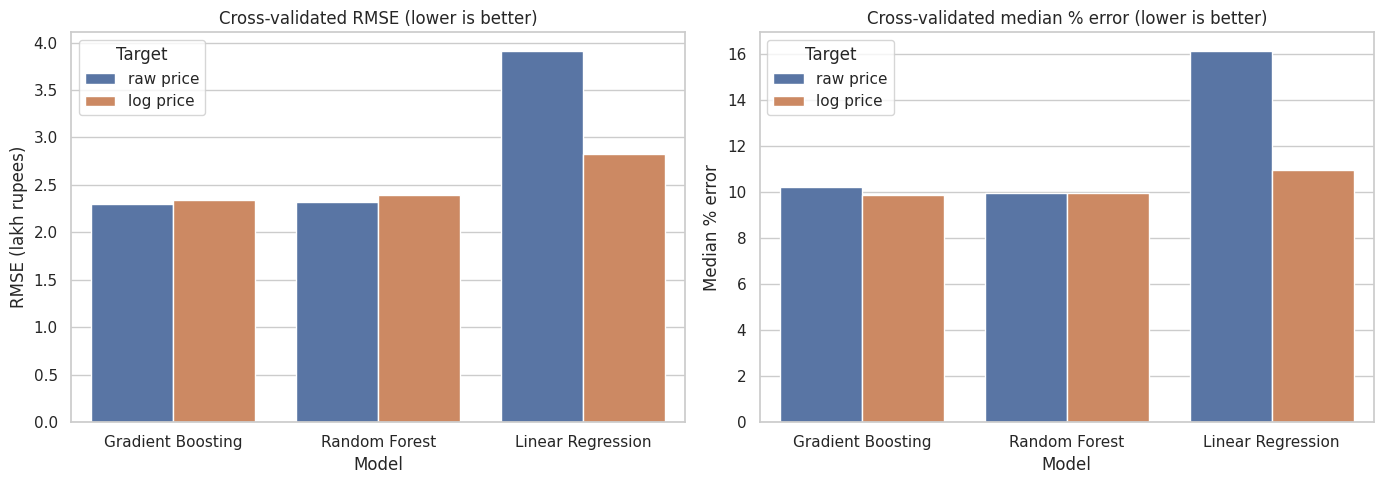

In [8]:
# Chart: cross-validated RMSE and median % error for the 6 combinations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=cv_table, x="Model", y="CV RMSE (lakh)", hue="Target", ax=axes[0])
axes[0].set_title("Cross-validated RMSE (lower is better)")
axes[0].set_ylabel("RMSE (lakh rupees)")

sns.barplot(data=cv_table, x="Model", y="CV median % error", hue="Target", ax=axes[1])
axes[1].set_title("Cross-validated median % error (lower is better)")
axes[1].set_ylabel("Median % error")

save_fig("10_model_comparison_cv")

## 6. Choosing the winner

The winner is the combination with the lowest cross-validated RMSE. This is the standard measure named in the task and it is computed on training data only. We also look at the median % error, because RMSE is dominated by expensive cars and the two measures can disagree. The best two combinations by RMSE are carried to the tuning notebook.

In [9]:
# The table above is sorted by CV RMSE, so the first row is the winner
winner = cv_table.iloc[0]
shortlist = cv_table.iloc[:2][["Model", "Target"]]

print("Winner by cross-validated RMSE:", winner["Model"], "with", winner["Target"])
print("\nShortlist for tuning (notebook 05):")
print(shortlist.to_string(index=False))

# Does the median % error pick a different winner?
best_pct = cv_table.sort_values("CV median % error").iloc[0]
print("\nLowest median % error:", best_pct["Model"], "with", best_pct["Target"])

Winner by cross-validated RMSE: Gradient Boosting with raw price

Shortlist for tuning (notebook 05):
            Model    Target
Gradient Boosting raw price
    Random Forest raw price

Lowest median % error: Gradient Boosting with log price


## 7. Evaluation on the test set

Now each combination is trained on the full training set and tested on the 20% of cars that no model has seen. These scores show how well each setup works on new cars. They were **not** used to pick the winner.

In [10]:
start = time.time()
test_rows = []
test_predictions = {}     # keep the predictions for the charts below

for target_name in target_names:
    for model_name in base_models:
        model = build_model(model_name, target_name)
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)                  # always in rupees
        test_predictions[(model_name, target_name)] = predictions
        row = {"Model": model_name, "Target": target_name}
        row.update(evaluate(y_test, predictions))
        test_rows.append(row)
        print(f"Done: {model_name} ({target_name}) after {round(time.time() - start)} seconds")

test_table = pd.DataFrame(test_rows).sort_values("RMSE (lakh)").reset_index(drop=True)
test_table.round(3)

Done: Linear Regression (raw price) after 0 seconds
Done: Random Forest (raw price) after 11 seconds
Done: Gradient Boosting (raw price) after 14 seconds
Done: Linear Regression (log price) after 14 seconds
Done: Random Forest (log price) after 24 seconds
Done: Gradient Boosting (log price) after 27 seconds


,Model,Target,RMSE (lakh),MAE (lakh),R2,Median % error
0,Random Forest,raw price,5.840,1.082,0.736,10.019
1,Random Forest,log price,6.105,1.088,0.711,9.960
2,Gradient Boosting,raw price,6.446,1.146,0.678,10.270
3,Gradient Boosting,log price,6.495,1.160,0.673,9.893
4,Linear Regression,log price,7.219,1.232,0.597,11.404
5,Linear Regression,raw price,8.018,1.828,0.502,16.767


## 8. Where do the models make their biggest errors?

One overall number hides how a model does on different kinds of cars. We split the test cars into price bands and look at the median % error in each band, for the best model trained on log price and the best trained on raw price.

Best on log price: Gradient Boosting | Best on raw price: Gradient Boosting
Setup              Gradient Boosting, log price  Gradient Boosting, raw price
Price band (lakh)                                                            
under 3                                    14.2                          16.3
3 to 6                                      9.4                           9.8
6 to 10                                     8.4                           8.8
10 to 20                                   10.2                          10.1
over 20                                    12.3                          11.3

Test cars per band:
selling_price
under 3      445
3 to 6      1289
6 to 10      813
10 to 20     347
over 20      154


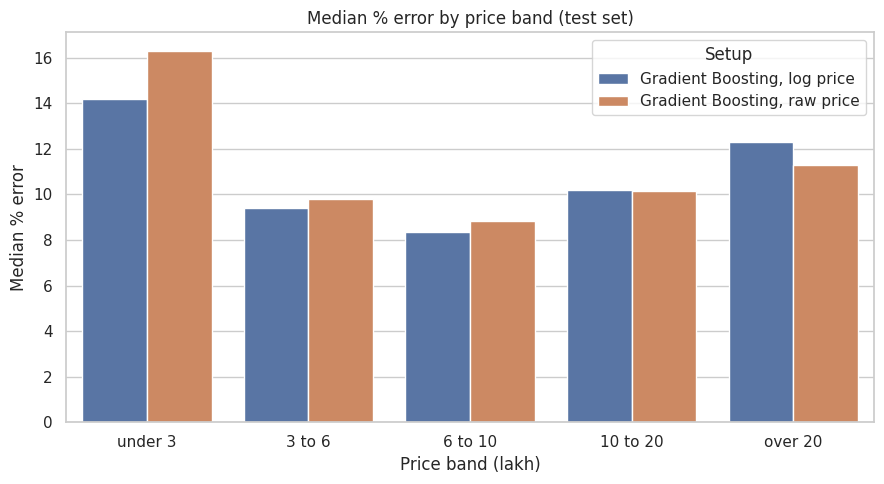

In [11]:
# The best model type for each target, by cross-validated RMSE
best_log = cv_table[cv_table["Target"] == "log price"].iloc[0]["Model"]
best_raw = cv_table[cv_table["Target"] == "raw price"].iloc[0]["Model"]
print("Best on log price:", best_log, "| Best on raw price:", best_raw)

# Price bands, using the real selling price of each test car (in lakh rupees)
bands = pd.cut(y_test / 100_000, bins=[0, 3, 6, 10, 20, np.inf],
               labels=["under 3", "3 to 6", "6 to 10", "10 to 20", "over 20"])

band_rows = []
for target_name, model_name in [("log price", best_log), ("raw price", best_raw)]:
    predictions = test_predictions[(model_name, target_name)]
    pct_error = np.abs(y_test.values - predictions) / y_test.values * 100
    by_band = pd.Series(pct_error).groupby(bands.values).median()
    for band, value in by_band.items():
        band_rows.append({"Price band (lakh)": band, "Setup": f"{model_name}, {target_name}",
                          "Median % error": value})
band_table = pd.DataFrame(band_rows)

# The same numbers as a small table
print(band_table.pivot(index="Price band (lakh)", columns="Setup", values="Median % error")
                .reindex(["under 3", "3 to 6", "6 to 10", "10 to 20", "over 20"]).round(1).to_string())

# How many test cars fall in each band
print("\nTest cars per band:")
print(bands.value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=band_table, x="Price band (lakh)", y="Median % error", hue="Setup", ax=ax)
ax.set_title("Median % error by price band (test set)")
save_fig("11_error_by_price_band")

## 9. Why is the test RMSE so much larger than the cross-validated RMSE?

Compare the two tables above. The cross-validated RMSE is around 2.3 lakh, but the test RMSE is much larger. The MAE and the median % error, on the other hand, are almost the same in both. That pattern points to a few extreme errors. RMSE squares every error, so a few huge errors dominate it. We look at the five largest errors of the winner.

In [12]:
winner_predictions = test_predictions[(winner["Model"], winner["Target"])]

# The 5 test cars where the winner was furthest off
largest = pd.DataFrame({
    "brand": clean.loc[y_test.index, "brand"],
    "model": clean.loc[y_test.index, "model"],
    "actual (lakh)": y_test / 100_000,
    "predicted (lakh)": winner_predictions / 100_000,
})
largest["error (lakh)"] = (largest["actual (lakh)"] - largest["predicted (lakh)"]).abs()
print(largest.sort_values("error (lakh)", ascending=False).head(5).round(1).to_string())

# Compare with the most expensive car the model saw during training
print("\nMost expensive training car (lakh):", y_train.max() / 100_000)
print("Test cars above that price:", (y_test > y_train.max()).sum())

# Diagnostic only (not a result): the scores if those cars are left out
within_range = (y_test <= y_train.max()).values
print("\nAll test cars:                ", {k: round(v, 3) for k, v in evaluate(y_test, winner_predictions).items()})
print("Without cars above the range:", {k: round(v, 3) for k, v in
      evaluate(y_test[within_range], winner_predictions[within_range]).items()})

               brand        model  actual (lakh)  predicted (lakh)  error (lakh)
3784         Ferrari    GTC4Lusso          395.0              94.0         301.0
10869    Rolls-Royce        Ghost          242.0              94.0         148.0
10889  Mercedes-Benz      S-Class          110.0              68.6          41.4
12872        Bentley  Continental           81.0              46.1          34.9
1740      Volkswagen         Polo            8.8              36.4          27.6

Most expensive training car (lakh): 145.0
Test cars above that price: 2

All test cars:                 {'RMSE (lakh)': np.float64(6.446), 'MAE (lakh)': 1.146, 'R2': 0.678, 'Median % error': np.float64(10.27)}
Without cars above the range: {'RMSE (lakh)': np.float64(2.156), 'MAE (lakh)': 0.999, 'R2': 0.925, 'Median % error': np.float64(10.27)}


## 10. Predicted vs actual price

For the overall winner, each point is one test car. A perfect model would put every point on the diagonal line.

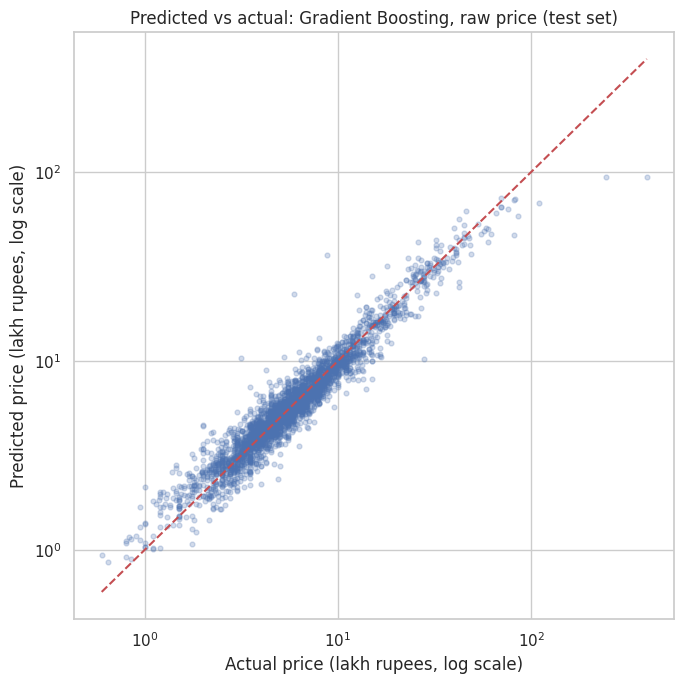

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test / 100_000, winner_predictions / 100_000, alpha=0.25, s=12, color="#4C72B0")

# The diagonal line where prediction = actual
low = min(y_test.min(), winner_predictions.min()) / 100_000
high = max(y_test.max(), winner_predictions.max()) / 100_000
ax.plot([max(low, 0.5), high], [max(low, 0.5), high], color="#C44E52", linestyle="--")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual price (lakh rupees, log scale)")
ax.set_ylabel("Predicted price (lakh rupees, log scale)")
ax.set_title(f"Predicted vs actual: {winner['Model']}, {winner['Target']} (test set)")

save_fig("12_predicted_vs_actual")

## 11. Findings

Numbers are rounded. Errors are in lakh rupees.

**Cross-validated comparison (used to choose the winner)**
- The three tree-based setups with the best scores are very close: Gradient Boosting on raw price (RMSE about 2.30), Random Forest on raw price (about 2.32), and Gradient Boosting on log price (about 2.34). Their R2 is about 0.92 and their typical (median) error is about 10%. The differences between them are small enough that we should not read much into the exact order.
- The winner by cross-validated RMSE is **Gradient Boosting trained on raw price**. Gradient Boosting with log price has a very slightly lower median % error (about 9.8% vs 10.2%), so the two measures do disagree a little, but only by a small amount.
- Linear Regression is clearly the weakest, as expected for a baseline. It does much better on log price (RMSE about 2.8, R2 0.88) than on raw price (about 3.9, R2 0.77). So the relationship between the features and price is closer to multiplicative than additive, which is what log price handles well. Trees do not need this help, which is why log price makes little difference for them.

**Test set**
- The test-set order differs from cross-validation: Random Forest is first on test RMSE (about 5.8 on raw price), and Gradient Boosting is about 6.5. Test R2 is about 0.74 and 0.68. These are much worse than the cross-validated numbers (RMSE about 2.3, R2 about 0.92), but the test MAE (about 1.1) and median % error (about 10%) are almost the same as in cross-validation.
- The reason is two cars. The test set contains a Ferrari GTC4Lusso (395 lakh) and a Rolls-Royce Ghost (242 lakh). The most expensive car in the training data is 145 lakh. The models predicted about 93 to 120 lakh for these two, so their errors are 150 to 300 lakh. RMSE squares errors, so these two cars alone raise the test RMSE from about 2.2 to about 6.5 (Gradient Boosting).
- If those two cars are left out, the Gradient Boosting test scores are RMSE about 2.2, R2 about 0.93, and median % error about 10.2%, in line with cross-validation. This is a diagnostic to understand the gap, not a result to report as the model's score. The honest test scores are the ones including them.
- This is a real weakness, not a bug: tree-based models cannot predict prices higher than the ones they were trained on, so extremely expensive luxury cars are badly underpredicted. Because these cars are so rare, test RMSE and R2 depend heavily on which of them landed in the test set. MAE and median % error are more stable measures here.

**Errors by price band**
- For a typical car the model is off by roughly 9% to 10% (3 to 10 lakh cars: about 9% to 10%). The percentage error is highest for the cheapest cars (under 3 lakh: about 14% to 16%), because a small rupee error is a large share of a low price. Above 10 lakh it is about 10% to 13%.
- Log price gives lower percentage errors for the cheapest cars (about 14% vs 16%), and raw price does slightly better for the most expensive ones (about 11% vs 13% above 20 lakh).

**What this means for the next steps**
- The shortlist for tuning is Gradient Boosting and Random Forest, both on raw price.
- The setups are close, so tuning may change the ranking. Part 6 will again choose by cross-validation and not by the test set.
- The documentation should state clearly that the model is reliable for ordinary cars (about 10% typical error) and unreliable for ultra-luxury cars above the range of the training data.


## 12. Save the charts

Download the charts and put the PNG files in `reports/figures/`.

In [14]:
# In Colab, zip the charts and download them
import shutil

try:
    from google.colab import files
    shutil.make_archive("model_development_figures", "zip", "figures")
    files.download("model_development_figures.zip")
except ImportError:
    print("Not running in Colab, so the charts stay in the figures folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Summary

- Trained Linear Regression, Random Forest, and Gradient Boosting on raw price and on log price (6 combinations) with default settings.
- Compared them with 5-fold cross-validation on the training data, and chose the winner from that, not from the test set.
- Reported test-set scores, looked at errors by price band, and checked where the largest test errors come from.

**Next:** notebook 05, tuning the shortlisted models and saving the final model.